**Environment setup:** Install the required NLP/model dependencies in Cell #1, then proceed directly to the notebook. No mandatory version-checking cell or routine restart. If Colab reports a binary compatibility error after package installation, restart the runtime once.


# L6 / E15 — E0-equivalent Word TF-IDF + SVD + Agglomerative

**Stage 1 | Agglomerative | 14,639 airline tweets**

Standalone Google Colab notebook. Generate fresh representations from the **redacted, text-only** CSV. Never load historical L1–L5 output matrices or cluster assignments. Save the new assignments **before** loading human sentiment annotations. Enter the labelled CSV path **only in Cell #9**.

**Research status:** This is an exploratory follow-up informed by earlier sentiment results, not an untouched independent evaluation. The same 14,639 tweet corpus and K=3 are retained; this does not prove generalization or K=3 optimality.

**Comparability note:** Raw 29,792-dimensional sparse TF-IDF is impractical for conventional dense GMM and full hierarchical clustering. Both E14 and E15 therefore use the **same** fresh 50-dimensional TruncatedSVD + L2-normalized representation. This is not an algorithm-only comparison with E0 K-means, which used the original sparse vectors. E8/E9 already tested similar settings; these notebooks are independently runnable versions for your four-stage consolidation.

In [1]:
# 1 — Install dependencies for E15
%pip install -q emoji num2words wordninja wordfreq symspellpy vaderSentiment gensim


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**Run sequentially.** Model packages and remote checkpoints may change; the notebook records installed versions and model IDs. No labelled source is used before Cell #9.

In [2]:
# 2 — Input and output locations: text-only clustering source
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
INPUT_CSV = Path('/content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E15')
assert INPUT_CSV.is_file(), f'Missing redacted text CSV: {INPUT_CSV}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Clustering input:', INPUT_CSV)
print('Outputs:', OUTPUT_DIR)

Mounted at /content/drive
Clustering input: /content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv
Outputs: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E15


In [3]:
# 3 — Read text only; preserve original row positions
import numpy as np, pandas as pd, json, hashlib, platform, datetime
import importlib.metadata as im

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw = pd.read_csv(INPUT_CSV, usecols=['text'], dtype={'text':'string'})
assert raw['text'].notna().all(), 'Null source tweets'
assert len(raw) == 14639, f'Expected 14639 tweets, got {len(raw)}'
texts = raw['text'].astype(str).tolist()
source_row = np.arange(len(texts), dtype=np.int64)
source_sha = sha256_file(INPUT_CSV)
text_digest = hashlib.sha256(json.dumps(texts, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Tweets:', len(texts), '| SHA256:', source_sha)

Tweets: 14639 | SHA256: a41aeefcff9740c090153f608691d345c84f59084e40f03169c2f667df66578e


In [4]:
# 4 — Clone reusable GitHub source code; no historical matrices
import subprocess, sys
REPO_DIR = Path('/content/l6_source_code')
if not (REPO_DIR / '.git').is_dir():
    assert not REPO_DIR.exists(), 'Unexpected checkout folder'
    subprocess.run(['git','clone','--depth','1','https://github.com/frankie-chew-nus/sentiment-clustering-ml.git',str(REPO_DIR)],check=True)
GIT_REVISION = subprocess.check_output(['git','-C',str(REPO_DIR),'rev-parse','HEAD'],text=True).strip()
sys.path.insert(0,str(REPO_DIR))
from preprocessing import preprocess_text
print('Git commit:', GIT_REVISION)

Git commit: 214b65610fcde724ebf1cbcb8d7ab889347512e6


In [5]:
# 5 — Explicit E0-equivalent preprocessing; fresh text only
PREPROCESS_CONFIG = {
    'decode_html_entities': True,
    'remove_urls': True,
    'replace_airline_mentions': True,
    'remove_other_mentions': True,
    'replace_airline_hashtags': True,
    'replace_airline_names': True,
    'strip_hashtag_symbols': True,
    'hashtag_segmentation_mode': 'none',
    'hashtag_segmentation_min_token_length': 7,
    'expand_contractions': True,
    'convert_numbers': False,
    'lowercase': True,
    'punctuation_mode': 'keep',
    'emoji_mode': 'describe',
    'segmentation_mode': 'none',
    'correct_spelling': False,
    'lemmatize': False,
    'remove_stopwords': False,
    'normalize_whitespace': True,
}
processed_texts = [preprocess_text(t, PREPROCESS_CONFIG) for t in texts]
assert len(processed_texts) == len(texts)
assert all(isinstance(t,str) and t.strip() for t in processed_texts)
print('Preprocessed rows:',len(processed_texts))

Preprocessed rows: 14639


In [6]:
# 6 — E0 word TF-IDF: unigrams + bigrams, fresh fit
from sklearn.feature_extraction.text import TfidfVectorizer
TFIDF_CONFIG = dict(analyzer='word', ngram_range=(1,2), min_df=2,
                    max_df=0.95, max_features=30000, sublinear_tf=True,
                    norm='l2', use_idf=True, lowercase=False, dtype=np.float64)
vectorizer = TfidfVectorizer(**TFIDF_CONFIG)
X = vectorizer.fit_transform(processed_texts).tocsr()
assert X.shape[0] == len(texts) and np.isfinite(X.data).all()
print('TF-IDF:', X.shape, '| nonzeros:', X.nnz)

TF-IDF: (14639, 29792) | nonzeros: 371747


In [7]:
# 7 — K=3 clustering, without access to sentiment labels
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
SVD_CONFIG = {'n_components':50, 'n_iter':7, 'random_state':5001}
svd = TruncatedSVD(**SVD_CONFIG)
X_model = Normalizer(norm='l2').fit_transform(svd.fit_transform(X))
print('SVD retained variance:',float(svd.explained_variance_ratio_.sum()))
assert X_model.shape == (len(texts),50)

from sklearn.cluster import AgglomerativeClustering
MODEL_CONFIG = dict(n_clusters=3, linkage='ward', metric='euclidean')
model = AgglomerativeClustering(**MODEL_CONFIG)
clusters = model.fit_predict(X_model)
MODEL_DIAGNOSTICS = {'linkage':'ward', 'distance':'euclidean'}
SILHOUETTE_METRIC='euclidean'

assert np.isfinite(X_model).all()
assert len(clusters) == len(texts)
assert set(np.unique(clusters)) == {0,1,2}, 'Three nonempty clusters required'
print('Cluster sizes:',dict(zip(*np.unique(clusters,return_counts=True))))

SVD retained variance: 0.09565404939000555
Cluster sizes: {np.int64(0): np.int64(13597), np.int64(1): np.int64(476), np.int64(2): np.int64(566)}


In [8]:
# 8 — Save label-blind assignments BEFORE opening the labelled CSV
import sklearn, scipy
versions = {k:im.version(k) for k in ['numpy','pandas','scikit-learn','scipy']}
manifest = {
    'experiment':'E15', 'stage':'statistical_tf_idf',
    'algorithm':'Agglomerative', 'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'source_csv':INPUT_CSV.name,'source_sha256':source_sha,
    'text_sequence_sha256':text_digest,'n_rows':len(texts),
    'row_alignment':'original positional row, no sort or drop',
    'preprocessing':PREPROCESS_CONFIG,
    'input_shape':list(X.shape),'model_shape':list(X_model.shape),
    'model_config':MODEL_CONFIG,'model_diagnostics':MODEL_DIAGNOSTICS,
    'svd_config':SVD_CONFIG,'silhouette_metric':SILHOUETTE_METRIC,
    'versions':versions,'python':platform.python_version(),
    'cluster_sizes':np.bincount(clusters,minlength=3).tolist(),
}
manifest["git_revision"] = GIT_REVISION
manifest["tfidf_config"] = {k:(list(v) if isinstance(v,tuple) else str(v) if isinstance(v,type) else v) for k,v in TFIDF_CONFIG.items()}
manifest["svd_variance_retained"] = float(svd.explained_variance_ratio_.sum())
assign_path = OUTPUT_DIR/'E15_seed5001_assignments.csv'
pd.DataFrame({'source_row':source_row,'cluster_id':clusters}).to_csv(assign_path,index=False)
manifest['assignments_sha256'] = sha256_file(assign_path)
(OUTPUT_DIR/'E15_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Frozen assignments:',assign_path)

Frozen assignments: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E15/E15_seed5001_assignments.csv


In [9]:
# 9 — ONLY labelled-data access cell: enter path manually
LABEL_CSV = Path('/content/drive/MyDrive/MSI5001 project/Problem statement/Tweets.csv')
assert LABEL_CSV.is_file(), f'Labelled CSV missing: {LABEL_CSV}'
assert LABEL_CSV.resolve() != INPUT_CSV.resolve()
saved = pd.read_csv(assign_path)
assert np.array_equal(saved['source_row'].to_numpy(),source_row)
assert np.array_equal(saved['cluster_id'].to_numpy(),clusters)
assert sha256_file(INPUT_CSV) == source_sha
label_texts = pd.read_csv(LABEL_CSV,usecols=['text'],dtype={'text':'string'})['text']
assert label_texts.notna().all()
assert label_texts.astype(str).tolist() == texts, 'Tweet text/order mismatch'
labels = pd.read_csv(LABEL_CSV,usecols=['airline_sentiment'],
                     dtype={'airline_sentiment':'string'})['airline_sentiment']
assert labels.notna().all() and len(labels)==len(texts)
assert set(labels.unique()) == {'negative','neutral','positive'}
y_true = labels.astype(str).to_numpy()
y_pred = saved['cluster_id'].to_numpy()
print('Verified exact row alignment. Labels now available only for evaluation.')

Verified exact row alignment. Labels now available only for evaluation.


In [10]:
# 10 — External evaluation: mapping-free ARI/NMI; optimal mapping for class metrics
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (adjusted_rand_score,normalized_mutual_info_score,
                             precision_recall_fscore_support,accuracy_score)
CLASSES = ['negative','neutral','positive']
CONTINGENCY = pd.crosstab(pd.Series(y_pred,name='cluster_id'),
                          pd.Series(y_true,name='true_sentiment')).reindex(
                          index=[0,1,2],columns=CLASSES,fill_value=0)
counts = CONTINGENCY.to_numpy()
ri,ci = linear_sum_assignment(-counts)
mapping = {int(r):CLASSES[int(c)] for r,c in zip(ri,ci)}
mapped = np.array([mapping[int(c)] for c in y_pred])
precision,recall,f1,support = precision_recall_fscore_support(
    y_true,mapped,labels=CLASSES,zero_division=0)
per_class = pd.DataFrame({'sentiment':CLASSES,'precision':precision,
                          'recall':recall,'f1':f1,'support':support})
composition = CONTINGENCY.div(CONTINGENCY.sum(axis=1),axis=0)
metrics = {'experiment':'E15','n':len(y_true),'ari':float(adjusted_rand_score(y_true,y_pred)),
           'nmi':float(normalized_mutual_info_score(y_true,y_pred)),
           'purity':float(counts.max(axis=1).sum()/counts.sum()),
           'mapped_accuracy':float(accuracy_score(y_true,mapped)),
           'macro_f1':float(np.mean(f1)),
           'majority_class_baseline':float(max(np.unique(y_true,return_counts=True)[1])/len(y_true)),
           'cluster_to_sentiment_mapping':mapping}
print('Metrics:',metrics)
display(CONTINGENCY,composition,per_class)

Metrics: {'experiment': 'E15', 'n': 14639, 'ari': 0.1088513596353988, 'nmi': 0.09003288033733596, 'purity': 0.6601543821299269, 'mapped_accuracy': 0.6400710431040372, 'macro_f1': 0.35623639466124174, 'majority_class_baseline': 0.6269553931279459, 'cluster_to_sentiment_mapping': {0: 'negative', 1: 'positive', 2: 'neutral'}}


true_sentiment,negative,neutral,positive
cluster_id,,,
0,8957,2985,1655
1,61,58,357
2,160,56,350


true_sentiment,negative,neutral,positive
cluster_id,,,
0,0.658748,0.219534,0.121718
1,0.128151,0.121849,0.750000
2,0.282686,0.098940,0.618375


,sentiment,precision,recall,f1,support
0,negative,0.658748,0.975921,0.786564,9178
1,neutral,0.098940,0.018070,0.030559,3099
2,positive,0.750000,0.151143,0.251586,2362


In [11]:
# 11 — Sampled silhouette: fixed label-blind 2,000-row sample
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(5001)
sample_rows = np.sort(rng.choice(len(clusters),size=min(2000,len(clusters)),replace=False))
sample_labels = clusters[sample_rows]
unique, sizes = np.unique(sample_labels,return_counts=True)
if len(unique)<2 or len(unique)>=len(sample_rows):
    sil = None
    print('Silhouette N/A: sampled rows contain fewer than 2 clusters')
else:
    sil = float(silhouette_score(X_model[sample_rows],sample_labels,metric=SILHOUETTE_METRIC))
    if min(sizes)<=1:
        print('WARNING: sampled singleton cluster; silhouette can be misleading')
metrics.update({'silhouette_2000':sil,'silhouette_metric':SILHOUETTE_METRIC,
                'silhouette_sample_size':len(sample_rows),'silhouette_sample_seed':5001,
                'sample_cluster_sizes':dict(zip(map(int,unique),map(int,sizes)))})
print('Silhouette:',sil)

Silhouette: 0.040421806947314766


In [12]:
# 12 — Save evidence (Drive only; no GitHub writes)
CONTINGENCY.to_csv(OUTPUT_DIR/'E15_contingency.csv')
composition.to_csv(OUTPUT_DIR/'E15_sentiment_composition.csv')
per_class.to_csv(OUTPUT_DIR/'E15_per_class_metrics.csv',index=False)
pd.DataFrame({'source_row':source_row,'cluster_id':y_pred,
              'mapped_sentiment':mapped,'true_sentiment':y_true}).to_csv(
              OUTPUT_DIR/'E15_evaluation_rows.csv',index=False)
(OUTPUT_DIR/'E15_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Evidence saved:',OUTPUT_DIR)

Evidence saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E15


## How to interpret the results

- **ARI** (chance-adjusted, higher better; 1 perfect, 0 near chance): agreement between clusters and true sentiment groups. It does not need a cluster-to-class mapping.
- **NMI** (0–1, higher better): shared information between clusters and sentiment classes, without mapping.
- **Purity** (0–1, higher better): proportion in the majority sentiment of each cluster; can be inflated by the 62.7% negative class prevalence.
- **Optimally mapped accuracy** (0–1, higher better): one-to-one matching of cluster IDs to negative/neutral/positive by Hungarian assignment. Not unseen-data classification accuracy.
- **Precision / recall / F1 per class**: correctness, coverage and their harmonic mean after mapping; **Macro F1** gives all three classes equal weight.
- **Silhouette** (−1 to 1): compactness/separation within the numerical feature space, **not** sentiment accuracy. Different distance metrics, dimensionalities and unbalanced clusters complicate cross-experiment comparisons.
- **Contingency matrix**: cluster-by-true-sentiment counts. Look for different dominant sentiments across clusters, not merely bright cells caused by the majority class.
- **Composition bars**: within-cluster percentages. Look for three distinct sentiment profiles.

The data are imbalanced (9,178 negative, 3,099 neutral, 2,362 positive). No cluster number is presumed to mean a particular sentiment. E0–E19 use the same corpus and most follow-ups are exploratory; conclusions are not independently validated on unseen tweets.

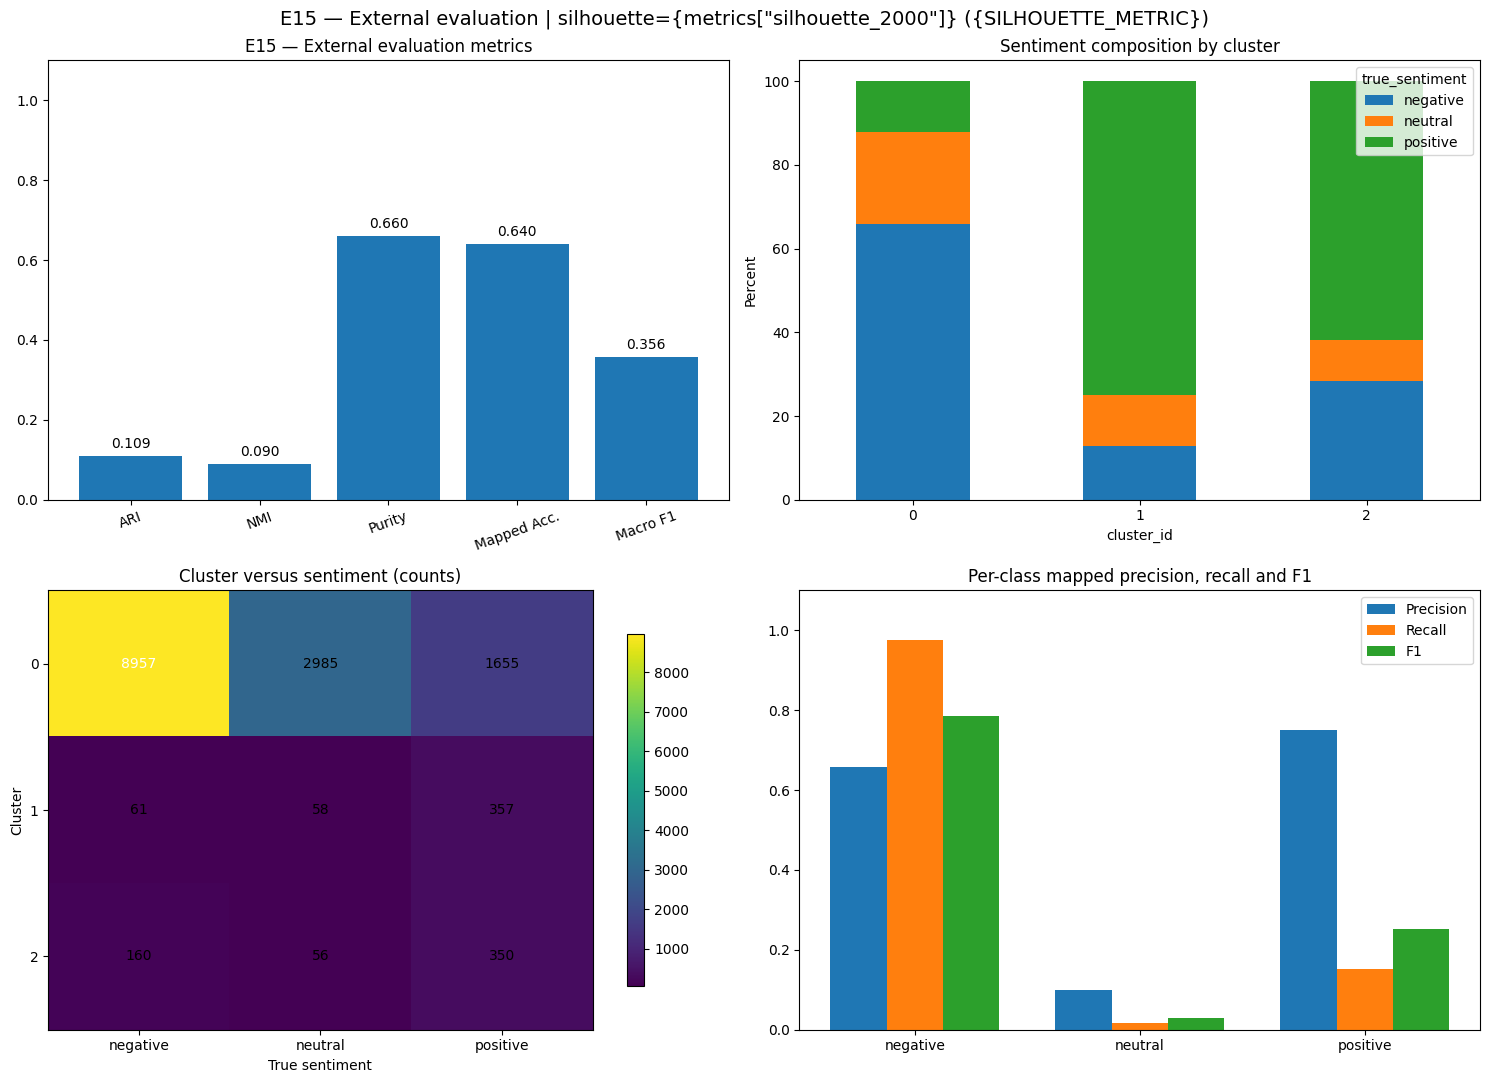

Saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E15/figures/E15_external_evaluation.png


In [13]:
# 13 — Four visual panels: scores, composition, contingency and per-class F1
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(15,11))
keys=['ARI','NMI','Purity','Mapped Acc.','Macro F1']
vals=[metrics['ari'],metrics['nmi'],metrics['purity'],metrics['mapped_accuracy'],metrics['macro_f1']]
axes[0,0].bar(keys,vals);axes[0,0].set_ylim(0,1.1)
axes[0,0].set_title('E15 — External evaluation metrics')
axes[0,0].tick_params(axis='x',rotation=20)
for i,v in enumerate(vals): axes[0,0].text(i,v+0.02,f'{v:.3f}',ha='center')
(composition*100).plot(kind='bar',stacked=True,ax=axes[0,1])
axes[0,1].set_title('Sentiment composition by cluster')
axes[0,1].set_ylabel('Percent');axes[0,1].tick_params(axis='x',rotation=0)
mat=CONTINGENCY.to_numpy()
im=axes[1,0].imshow(mat,aspect='auto',cmap='viridis')
axes[1,0].set_xticks(range(3),CLASSES);axes[1,0].set_yticks(range(3),[0,1,2])
axes[1,0].set_xlabel('True sentiment');axes[1,0].set_ylabel('Cluster')
axes[1,0].set_title('Cluster versus sentiment (counts)')
for i in range(3):
    for j in range(3): axes[1,0].text(j,i,str(mat[i,j]),ha='center',va='center',color='white' if mat[i,j]>mat.max()/2 else 'black')
fig.colorbar(im,ax=axes[1,0],shrink=.8)
x=np.arange(3);w=.25
axes[1,1].bar(x-w,precision,w,label='Precision');axes[1,1].bar(x,recall,w,label='Recall');axes[1,1].bar(x+w,f1,w,label='F1')
axes[1,1].set_xticks(x,CLASSES);axes[1,1].set_ylim(0,1.1);axes[1,1].legend()
axes[1,1].set_title('Per-class mapped precision, recall and F1')
fig.suptitle('E15 — External evaluation | silhouette={metrics["silhouette_2000"]} ({SILHOUETTE_METRIC})',fontsize=14)
plt.tight_layout()
fig_dir=OUTPUT_DIR/'figures';fig_dir.mkdir(exist_ok=True,parents=True)
fig.savefig(fig_dir/'E15_external_evaluation.png',dpi=200,bbox_inches='tight')
plt.show()
print('Saved:',fig_dir/'E15_external_evaluation.png')